In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

HO_TEN = "TRẦN THỊ MỸ DUNG"
MSSV = "6451071008"

np.random.seed(42)
tf.random.set_seed(42)

def thong_tin(cau):
    print(f"Họ tên: {HO_TEN}")
    print(f"MSSV: {MSSV}")
    print(f"BÀI 3 - CÂU {cau}")
    print("-" * 50)

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

print("Khởi tạo dữ liệu thành công!")
print("Train:", train_images.shape)
print("Test:", test_images.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Khởi tạo dữ liệu thành công!
Train: (60000, 28, 28)
Test: (10000, 28, 28)


In [2]:

# Câu d: Xây dựng và biên dịch mô hình Neural Network
thong_tin("d")

def create_model():
    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation="relu"),
        Dropout(0.2),
        Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_demo = create_model()
model_demo.summary()

print("Đã tạo mô hình thành công!")


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 3 - CÂU d
--------------------------------------------------


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Đã tạo mô hình thành công!


In [3]:

# Câu e: Huấn luyện mô hình bằng K-Fold Cross Validation
thong_tin("e")

kfold = KFold(n_splits=10, shuffle=True, random_state=42)

models = []
accuracy_per_fold = []
loss_per_fold = []

for fold_no, (train_idx, val_idx) in enumerate(kfold.split(train_images), start=1):
    print(f"\n========== FOLD {fold_no}/10 ==========")

    tf.keras.backend.clear_session()
    model = create_model()

    X_train_fold = train_images[train_idx]
    X_val_fold = train_images[val_idx]
    y_train_fold = train_labels[train_idx]
    y_val_fold = train_labels[val_idx]

    model.fit(
        X_train_fold,
        y_train_fold,
        epochs=5,
        batch_size=32,
        validation_data=(X_val_fold, y_val_fold),
        verbose=1
    )

    loss, accuracy = model.evaluate(
        X_val_fold,
        y_val_fold,
        verbose=0
    )

    models.append(model)
    accuracy_per_fold.append(accuracy)
    loss_per_fold.append(loss)

    print(f"Fold {fold_no} - Accuracy: {accuracy:.4f}")
    print(f"Fold {fold_no} - Loss: {loss:.4f}")

print("\nKẾT QUẢ 10 FOLD:")
for i in range(10):
    print(f"Fold {i+1}: Accuracy = {accuracy_per_fold[i]:.4f}, Loss = {loss_per_fold[i]:.4f}")


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 3 - CÂU e
--------------------------------------------------

========== FOLD 1/10 ==========
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9096 - loss: 0.3099 - val_accuracy: 0.9573 - val_loss: 0.1467
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9564 - loss: 0.1480 - val_accuracy: 0.9700 - val_loss: 0.1033
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9656 - loss: 0.1126 - val_accuracy: 0.9728 - val_loss: 0.0859
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9732 - loss: 0.0911 - val_accuracy: 0.9770 - val_loss: 0.0759
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9764 - loss: 0.0752 - val_accuracy: 0.9800 - val_loss: 0.0715
Fold 1 - Accuracy: 0.9800
Fold 1 - Loss: 0.0715

========== FOLD 2/10 ==========
Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9111 - loss: 0.3109 - val_accuracy: 0.9527 - val_loss: 0.1718
Epoch

In [4]:

# Câu f: Tính trung bình và độ lệch chuẩn Accuracy, Loss
thong_tin("f")

print(f"Mean Accuracy: {np.mean(accuracy_per_fold):.4f}")
print(f"Standard Deviation Accuracy: {np.std(accuracy_per_fold):.4f}")
print(f"Mean Loss: {np.mean(loss_per_fold):.4f}")
print(f"Standard Deviation Loss: {np.std(loss_per_fold):.4f}")


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 3 - CÂU f
--------------------------------------------------
Mean Accuracy: 0.9742
Standard Deviation Accuracy: 0.0029
Mean Loss: 0.0865
Standard Deviation Loss: 0.0084


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 3 - CÂU g
--------------------------------------------------


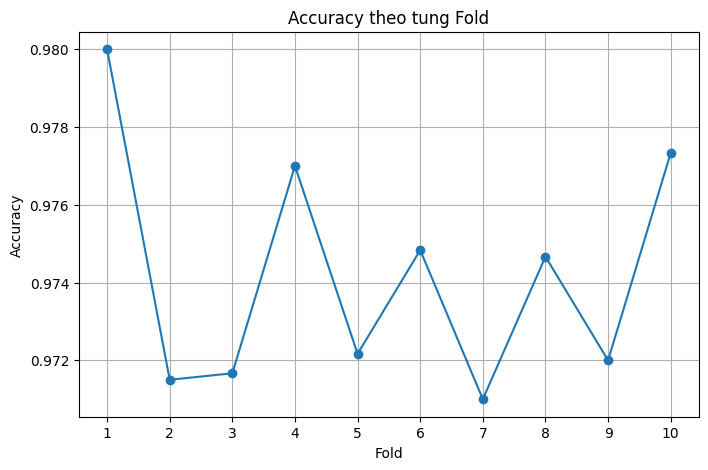

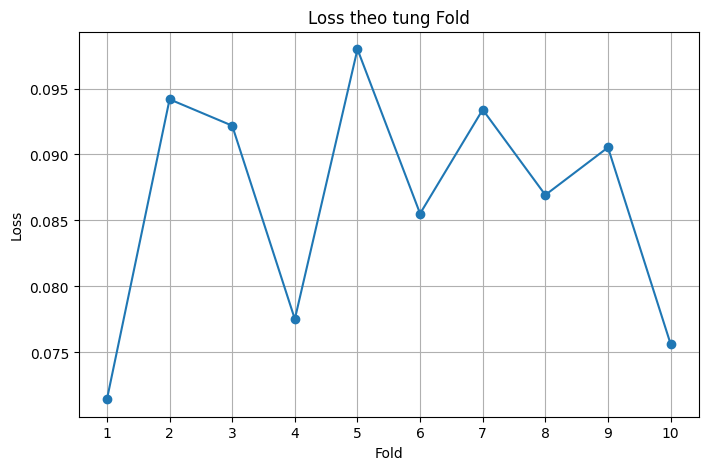

In [5]:

# Câu g: Vẽ biểu đồ Accuracy và Loss theo từng fold
thong_tin("g")

folds = range(1, 11)

plt.figure(figsize=(8, 5))
plt.plot(folds, accuracy_per_fold, marker="o")
plt.title("Accuracy theo tung Fold")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.xticks(list(folds))
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(folds, loss_per_fold, marker="o")
plt.title("Loss theo tung Fold")
plt.xlabel("Fold")
plt.ylabel("Loss")
plt.xticks(list(folds))
plt.grid(True)
plt.show()


In [6]:

# Câu h: Chọn mô hình Accuracy cao nhất để dự đoán
thong_tin("h")

best_index = np.argmax(accuracy_per_fold)
best_model = models[best_index]

print("Fold tốt nhất:", best_index + 1)
print("Validation Accuracy:", accuracy_per_fold[best_index])

y_prob = best_model.predict(test_images)
y_pred = np.argmax(y_prob, axis=1)

print("10 nhãn dự đoán:", y_pred[:10])
print("10 nhãn thực tế:", test_labels[:10])


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 3 - CÂU h
--------------------------------------------------
Fold tốt nhất: 1
Validation Accuracy: 0.9800000190734863
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
10 nhãn dự đoán: [7 2 1 0 4 1 4 9 6 9]
10 nhãn thực tế: [7 2 1 0 4 1 4 9 5 9]


In [7]:

# Câu i: Tính Accuracy của mô hình trên tập test
thong_tin("i")

acc_test = accuracy_score(test_labels, y_pred)

print(f"Accuracy: {acc_test:.4f}")
print(f"Accuracy (%): {acc_test * 100:.2f}%")


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 3 - CÂU i
--------------------------------------------------
Accuracy: 0.9772
Accuracy (%): 97.72%


In [8]:

# Câu j: Tính Precision, Recall và F1-score
thong_tin("j")

print(classification_report(
    test_labels,
    y_pred,
    labels=np.arange(10),
    target_names=[str(i) for i in range(10)],
    zero_division=0
))


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 3 - CÂU j
--------------------------------------------------
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.98      1032
           3       0.97      0.98      0.98      1010
           4       0.98      0.98      0.98       982
           5       0.98      0.97      0.98       892
           6       0.98      0.98      0.98       958
           7       0.98      0.97      0.97      1028
           8       0.98      0.96      0.97       974
           9       0.98      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 3 - CÂU k
--------------------------------------------------


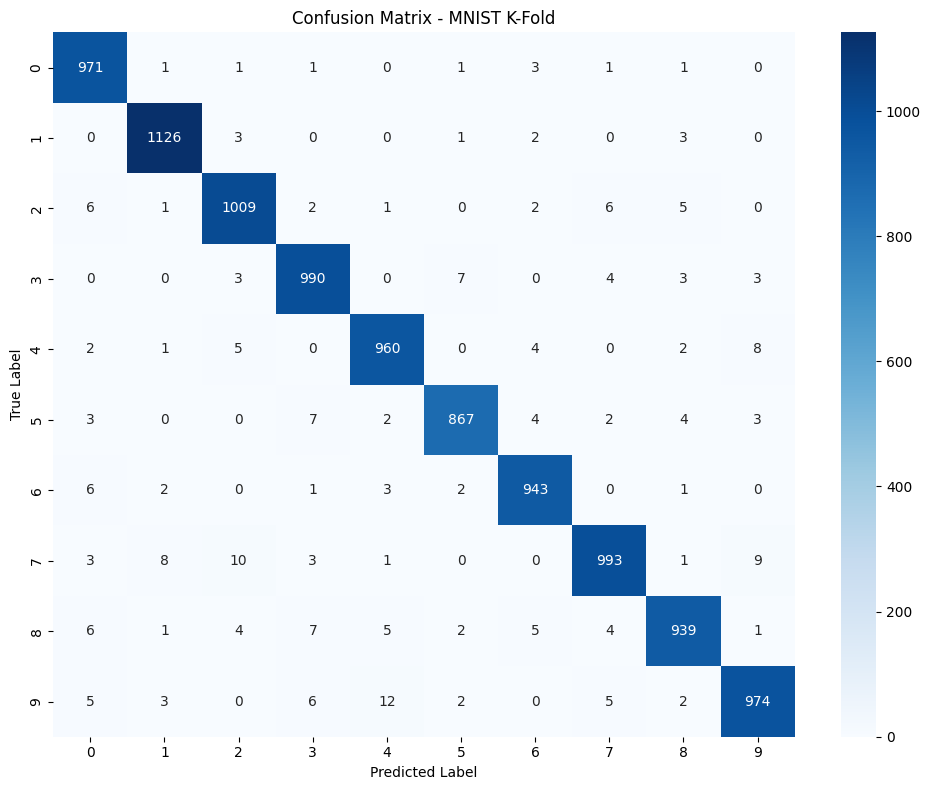

In [9]:

# Câu k: Hiển thị Confusion Matrix bằng Heatmap
thong_tin("k")

cm = confusion_matrix(test_labels, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Confusion Matrix - MNIST K-Fold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()


Họ tên: TRẦN THỊ MỸ DUNG
MSSV: 6451071008
BÀI 3 - CÂU l
--------------------------------------------------
Ảnh 1: Thực tế = 7, Dự đoán = 7
Ảnh 2: Thực tế = 2, Dự đoán = 2
Ảnh 3: Thực tế = 1, Dự đoán = 1
Ảnh 4: Thực tế = 0, Dự đoán = 0
Ảnh 5: Thực tế = 4, Dự đoán = 4


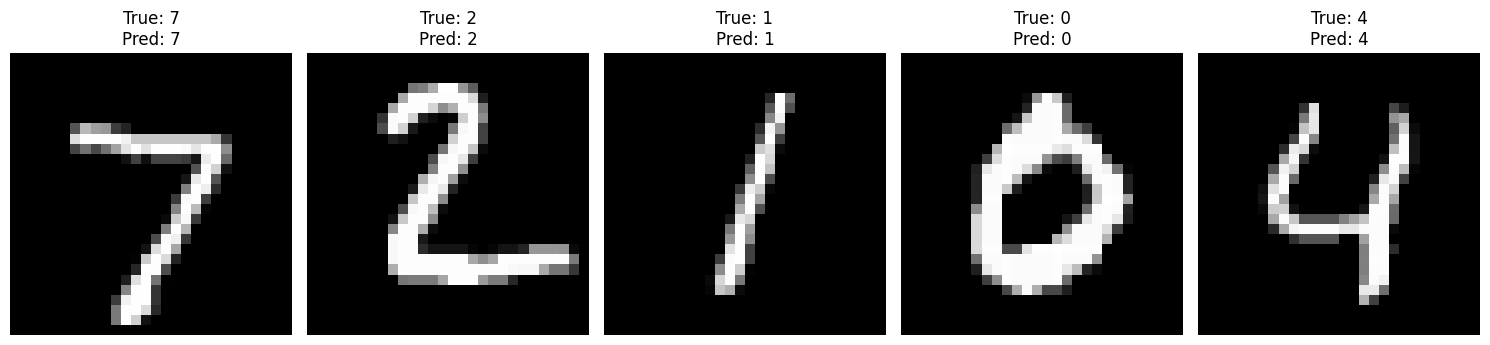

In [10]:

# Câu l: Hiển thị kết quả phân lớp 5 ảnh đầu tiên
thong_tin("l")

plt.figure(figsize=(15, 4))

for i in range(5):
    image = np.expand_dims(test_images[i], axis=0)
    prediction = best_model.predict(image, verbose=0)
    predicted_label = np.argmax(prediction, axis=1)[0]

    print(f"Ảnh {i+1}: Thực tế = {test_labels[i]}, Dự đoán = {predicted_label}")

    plt.subplot(1, 5, i + 1)
    plt.imshow(test_images[i], cmap="gray")
    plt.title(f"True: {test_labels[i]}\nPred: {predicted_label}")
    plt.axis("off")

plt.tight_layout()
plt.show()
